In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [19]:
df=pd.read_csv("Mall_Customers.csv")

df.head(5)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [20]:
# preprocess
df=df.dropna()


In [21]:
df=df.drop('CustomerID',axis=1)
df.head(5)

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [5]:
df.isnull().sum()
df.columns=df.columns.str.strip()

In [22]:
# convert categorical value in numerical values
df=pd.get_dummies(df,columns=['Genre'],drop_first=True,dtype='int')

df.columns

Index(['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Genre_Male'], dtype='object')

In [23]:
df.dtypes

Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
Genre_Male                int64
dtype: object

In [24]:
X=df[['Annual Income (k$)','Spending Score (1-100)']]

In [25]:
# scale
scaler=StandardScaler()

x_scales=scaler.fit_transform(X)

In [26]:
#kmeans

from sklearn.cluster import KMeans

In [26]:
print(dir(cluster))

['AffinityPropagation', 'AgglomerativeClustering', 'Birch', 'BisectingKMeans', 'DBSCAN', 'FeatureAgglomeration', 'HDBSCAN', 'KMeans', 'MeanShift', 'MiniBatchKMeans', 'OPTICS', 'SpectralBiclustering', 'SpectralClustering', 'SpectralCoclustering', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_affinity_propagation', '_agglomerative', '_bicluster', '_birch', '_bisect_k_means', '_dbscan', '_dbscan_inner', '_feature_agglomeration', '_hdbscan', '_hierarchical_fast', '_k_means_common', '_k_means_elkan', '_k_means_lloyd', '_k_means_minibatch', '_kmeans', '_mean_shift', '_optics', '_spectral', 'affinity_propagation', 'cluster_optics_dbscan', 'cluster_optics_xi', 'compute_optics_graph', 'dbscan', 'estimate_bandwidth', 'get_bin_seeds', 'k_means', 'kmeans_plusplus', 'linkage_tree', 'mean_shift', 'spectral_clustering', 'ward_tree']


2 0.3212707813918878
3 0.46658474419000145
4 0.4939069237513199
5 0.5546571631111091
6 0.5398800926790663
7 0.5281492781108291
8 0.4552147906587443
9 0.4570853966942764
10 0.4431713026508046


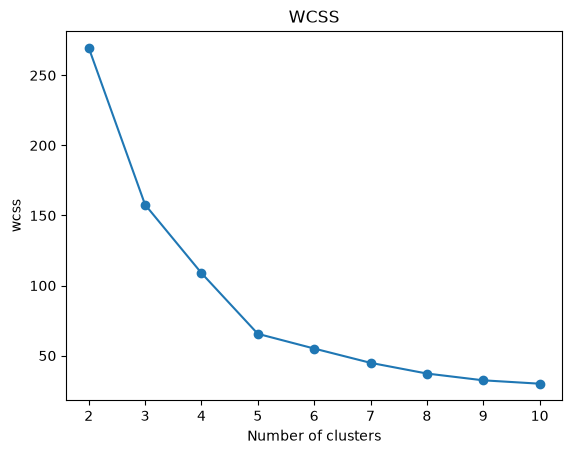

In [27]:
# print score
from sklearn.metrics import silhouette_score
wcss=[]

for i in range(2,11):
    kmeans=KMeans(n_clusters=i,random_state=42,n_init=10)
    kmeans.fit(x_scales)
    labels=kmeans.fit_predict(x_scales)
    score = silhouette_score(x_scales, labels)

    print(i, score)
    wcss.append(kmeans.inertia_)

plt.plot(range(2,11),wcss,marker='o')
plt.title("WCSS")
plt.xlabel("Number of clusters")
plt.ylabel("wcss")
plt.show()

In [31]:
Kmeans=KMeans(n_clusters=5,n_init=10,random_state=42)
kmeans_label=Kmeans.fit_predict(x_scales)

In [32]:
print("silhouette_score:",silhouette_score(x_scales,kmeans_label))

silhouette_score: 0.5546571631111091


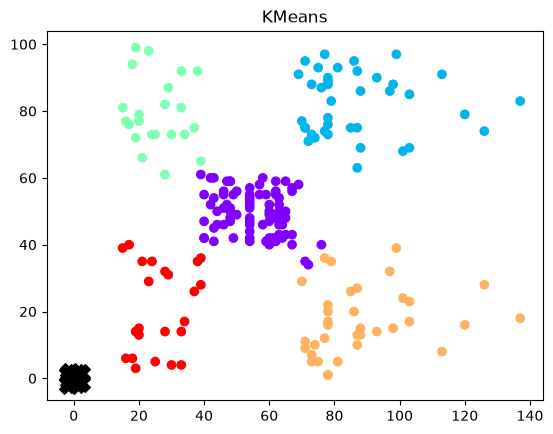

In [47]:
centroid=kmeans.cluster_centers_
plt.scatter(X['Annual Income (k$)'],
            X['Spending Score (1-100)'],
            c=kmeans_label,
            cmap='rainbow') # Label for the legend
plt.scatter(centroid[:, 0], 
            centroid[:, 1], 
            marker='X',        # Makes them look like big X's
            s=200,             # Size of the marker
            color="black",     # Color of the centroid
            label="Centroid")  # Label for the legend
plt.title("KMeans")
# plt.xlabel("Annual Income")
# plt.ylabel("Spending Score")
plt.show()

In [34]:
# Agglomative clustering

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage

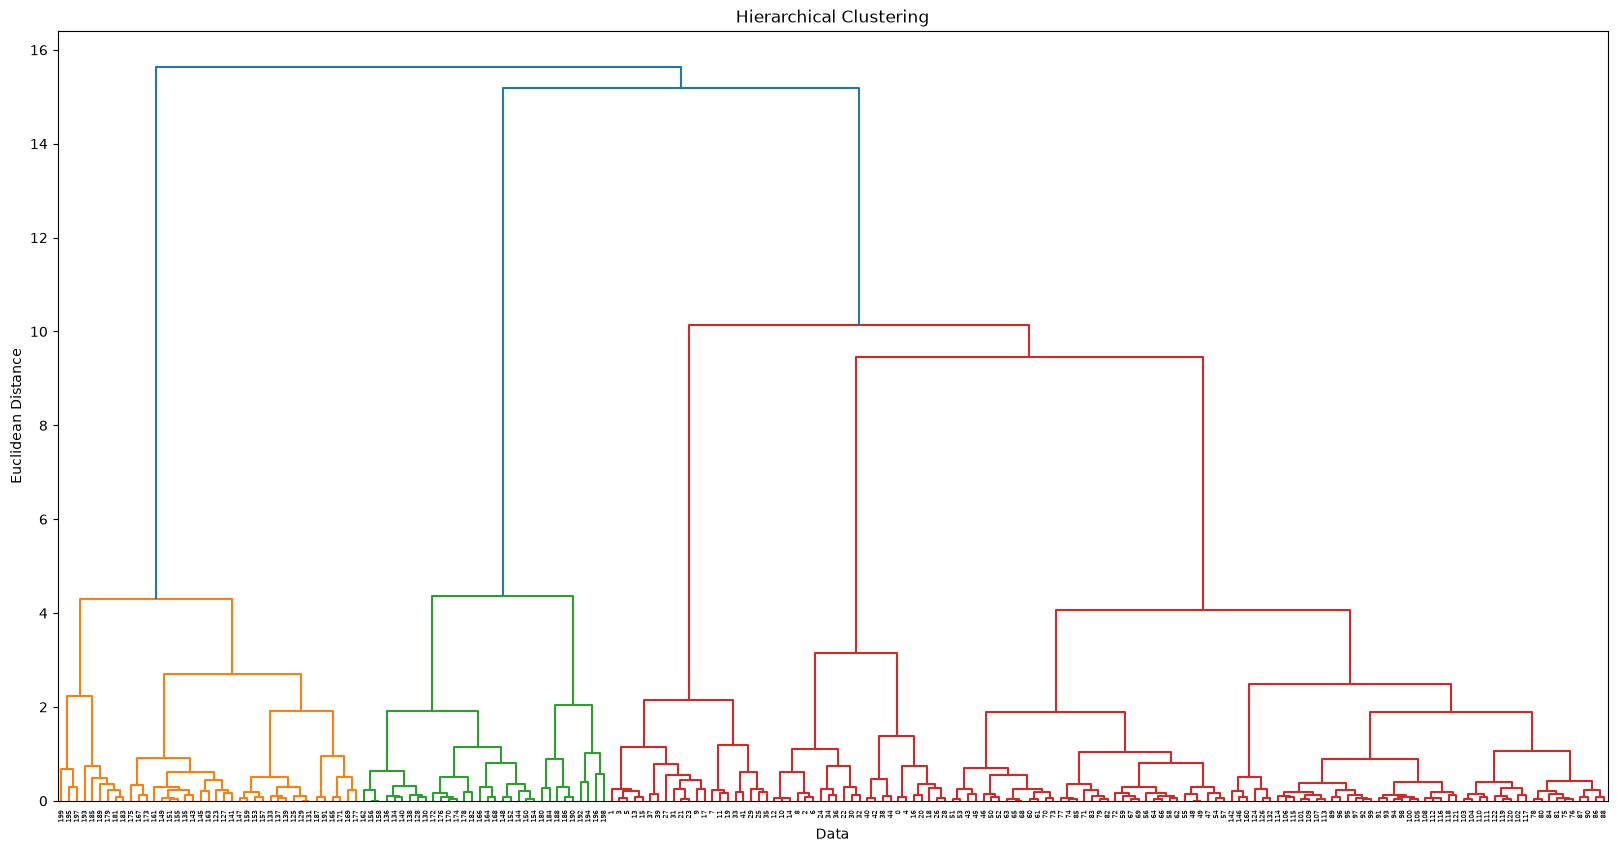

In [35]:
linked=linkage(x_scales,metric='euclidean',method='ward')
plt.figure(figsize=(20,10))

dendrogram(linked)
plt.title("Hierarchical Clustering")
plt.xlabel("Data")
plt.ylabel("Euclidean Distance")
plt.show()

In [41]:
hc=AgglomerativeClustering(n_clusters=5,linkage="ward")
hc_labels=hc.fit_predict(x_scales)

print("silhouette_score:",silhouette_score(x_scales,hc_labels))


silhouette_score: 0.5538089226688662


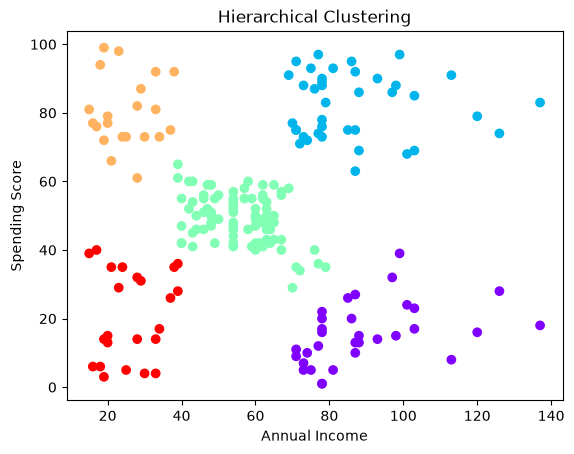

In [42]:

plt.scatter(X['Annual Income (k$)'],
            X['Spending Score (1-100)'],
            c=hc_labels,
            cmap='rainbow')

plt.title("Hierarchical Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()